# Nepal forest-fire analysis: full 238-location experiment

Run date: 4 November 2026. This notebook exposes the data audit, preparation decisions, actual model pipelines and saved experimental evidence. Earlier 2016 results were explored during this project, so this evaluation is retrospective.

Use the project Python environment documented in `research_full/README.md`. Set `REBUILD_RAW` and `RETRAIN` below to repeat computational stages. The default verifies and displays the completed run without overwriting fitted outputs.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import reanalysis_2026 as analysis
ROOT = Path.cwd()
DATA, OUT = analysis.DATA, analysis.OUT
REBUILD_RAW = False
RETRAIN = False
if REBUILD_RAW:
    data, features = analysis.ex.prepare()
else:
    data = pd.read_csv(DATA / 'forest_fire_grid_daily.csv', parse_dates=['date'])
    features = json.loads((DATA / 'feature_columns.json').read_text())
assert data.grid_id.nunique() == 238
assert not data.duplicated(['grid_id','date']).any()
assert np.isfinite(data[features].to_numpy()).all()
print('Rows:', len(data), 'Positive cell-days:', int(data.fire_detected.sum()), 'Features:', len(features))

Rows: 380562 Positive cell-days: 4399 Features: 21


## 1. Inspect the original data and audit

Administrative missing values are recorded but those fields are excluded from predictors. Exact duplicate rows differ from repeated detection keys. See the raw-audit and preparation-audit files for the coordinate range, excluded observations and target definition.

In [2]:
display(pd.Series(json.loads((OUT / 'raw_audit.json').read_text())))
display(pd.read_csv(OUT / 'source_missingness.csv'))
display(pd.Series(json.loads((DATA / 'preparation_audit.json').read_text())))
w = pd.read_csv(OUT / 'weather_audit.csv')
assert len(w) == 238 and w['rows'].eq(1827).all()
assert w['missing'].eq(0).all() and w['duplicate_dates'].eq(0).all()
assert w['finite'].all()
display(w.head())

columns                            [OBJECTID, LATITUDE, LONGITUDE, BRIGHTNESS, SC...
rows                                                                           13781
exact_duplicate_rows                                                               0
numeric_ranges                     {'LATITUDE': [26.426, 30.10937], 'LONGITUDE': ...
invalid_coordinate_rows                                                            0
distinct_returned_weather_cells                                                  238
weather_files                                                                    238
dtype: object

,Unnamed: 0,missing
0,OBJECTID,0
1,LATITUDE,0
2,LONGITUDE,0
3,BRIGHTNESS,0
4,SCAN,0
5,TRACK,0
6,ACQ_DATE,0
7,ACQ_TIME,0
8,SATELLITE,0
9,CONFIDENCE,0


source_fire_rows                                                                13781
weather_target_locations                                                          238
study_definition                    Forecast next-day recorded fire detection in f...
negative_definition                 No recorded detection; absence and satellite o...
invalid_acquisition_times                                                           0
unique_detection_rows                                                           13557
duplicate_detection_rows_removed                                                  224
outside_nepal_rows                                                                  1
within_nepal_nonforest_rows                                                      3298
forest_detection_rows                                                           10258
source_rows_per_year                {'2012': 3149, '2013': 1999, '2014': 2386, '20...
weather_complete_locations                            

,grid_id,rows,duplicate_dates,missing,finite,temperature_order_bad,humidity_order_bad,wind_order_bad
0,NP_01_32,1827,0,0,True,0,0,0
1,NP_02_27,1827,0,0,True,0,0,0
2,NP_02_28,1827,0,0,True,0,0,0
3,NP_02_29,1827,0,0,True,0,0,0
4,NP_02_30,1827,0,0,True,0,0,0


## 2. Feature construction and partition checks

Each target date uses weather only through its preceding day. Rainfall windows are 1, 7 and 30 days; seasonal sine/cosine and fixed forest/terrain summaries complete 21 predictors. Detection-derived fields are excluded. The raw preparation function is executable below; it is not a manually written substitute for the implementation.

In [3]:
import inspect
import prepare_assignment
print(inspect.getsource(prepare_assignment.main))
print('Predictors:', features)
assert not {'fire_detected','detection_count','national_detection_recorded','CONFIDENCE','FRP'} & set(features)
split_summary = data.groupby('split').fire_detected.agg(['size','sum','mean'])
display(split_summary)
tr = data[data.split.eq('train')]; va = data[data.split.eq('validation')]; te = data[data.split.eq('test')]
assert tr.date.max() < va.date.min() < va.date.max() < te.date.min()
display(pd.read_csv(OUT / 'feature_audit.csv'))

def main():
    geometry = json.loads(BOUNDARY.read_text())['features'][0]['geometry']
    polygon = shape(geometry)
    if not polygon.is_valid:
        raise ValueError('Invalid boundary polygon')
    terrain = terrain_features(geometry)
    fire = pd.read_csv(ROOT / 'data/sources/Active_Fire_Incidents_in_Nepal.csv')
    audit = {'source_fire_rows': len(fire), 'weather_target_locations': 238,
             'study_definition': 'Forecast next-day recorded fire detection in fixed 2011 forest mask',
             'negative_definition': 'No recorded detection; absence and satellite observation coverage unverified'}
    # The source follows MODIS acquisition fields. UTC interpretation is an assumption
    # pending source metadata, and is recorded in the report.
    date = pd.to_datetime(fire['ACQ_DATE'], errors='coerce')
    hhmm = pd.to_numeric(fire['ACQ_TIME'], errors='coerce')
    hour = hhmm // 100
    minute = hhmm % 100
    valid_time = date.notna() & hhmm.notna() & (hhmm == np.floor(

,size,sum,mean
split,,,
test,40460,1571,0.038828
train,253232,2625,0.010366
validation,86870,203,0.002337


,feature,skewness,minimum,maximum,missing
0,temperature_2m_mean_previous_day,-0.719463,-29.800000,36.600000,0
1,temperature_2m_max_previous_day,-0.674585,-28.000000,44.000000,0
2,relative_humidity_2m_mean_previous_day,-0.908541,6.000000,100.000000,0
3,relative_humidity_2m_min_previous_day,-0.288970,2.000000,99.000000,0
4,wind_speed_10m_mean_previous_day,2.458765,0.140000,8.170000,0
5,wind_speed_10m_max_previous_day,2.230415,0.320000,11.420000,0
6,precipitation_previous_1d_mm,6.418544,0.000000,367.700000,0
7,precipitation_previous_7d_mm,2.706539,0.000000,699.800000,0
8,precipitation_previous_30d_mm,1.719690,0.000000,1737.900000,0
9,temperature_mean_previous_7d,-0.715945,-28.714286,35.414286,0


## 3. Explore distributions, correlations and imbalance

No Gaussian distribution is assumed and plausible extremes are retained. Statistics used to choose representations come from training observations.

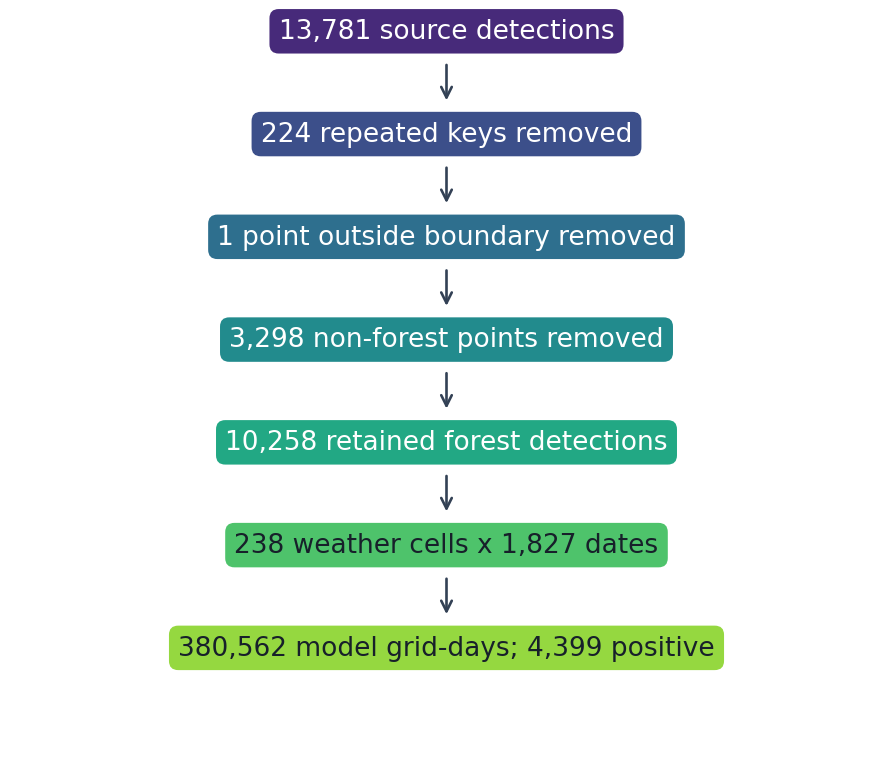

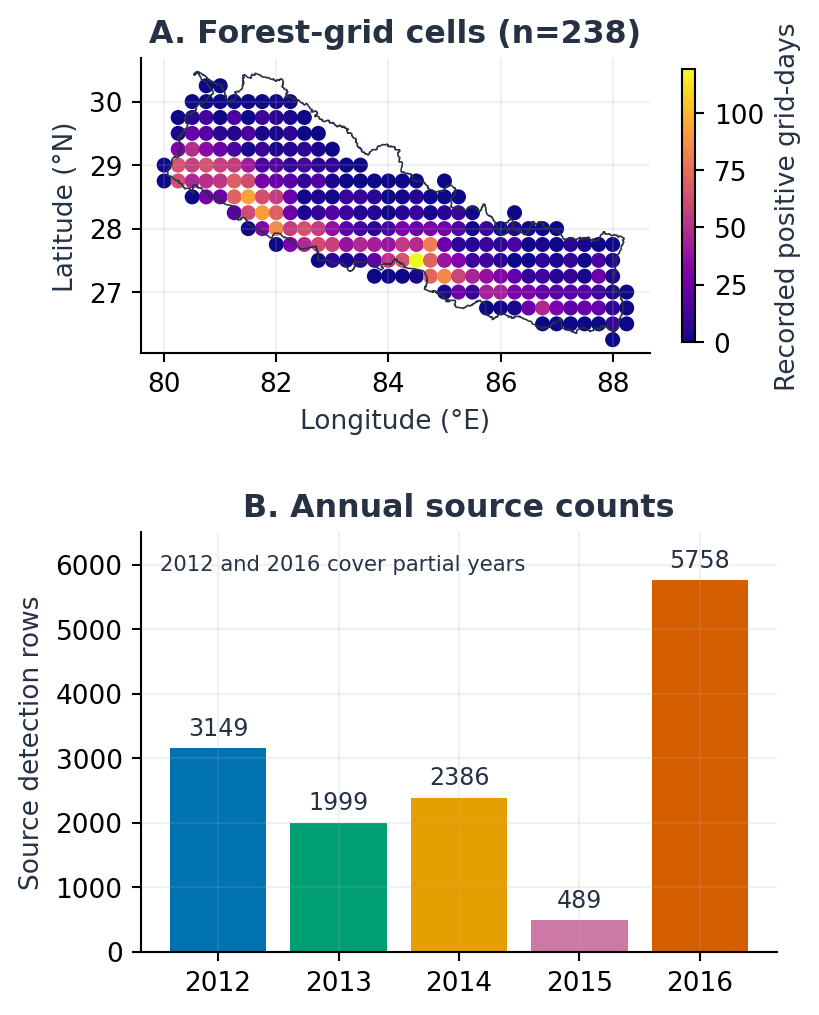

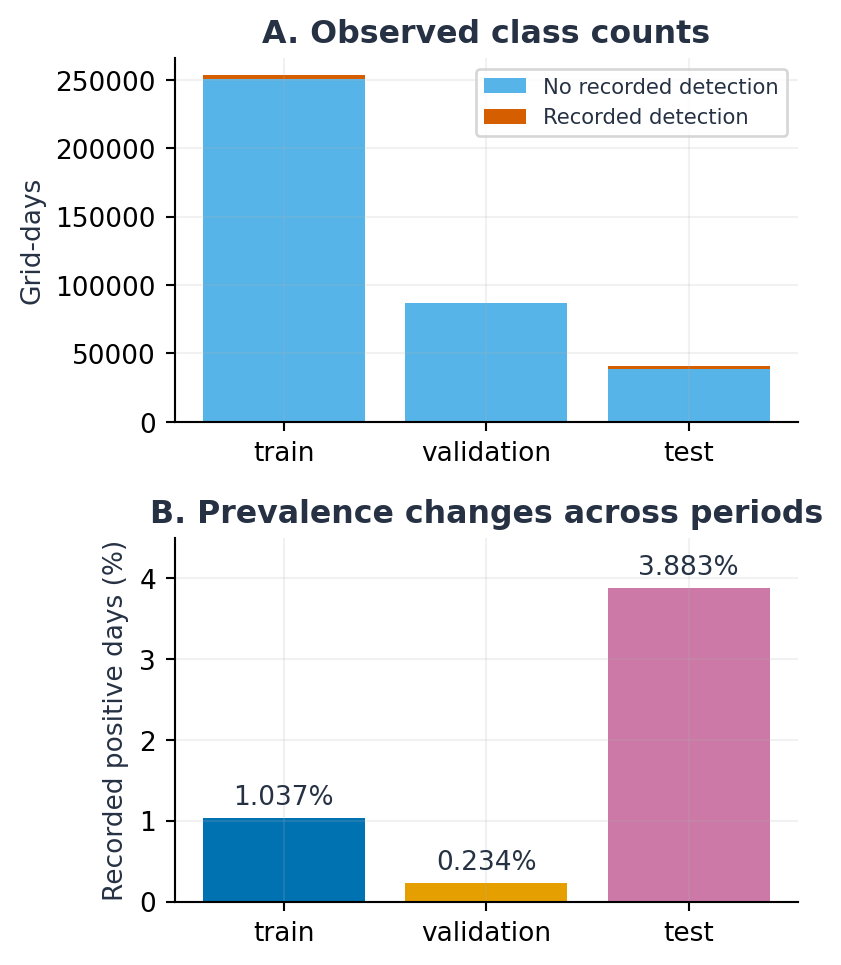

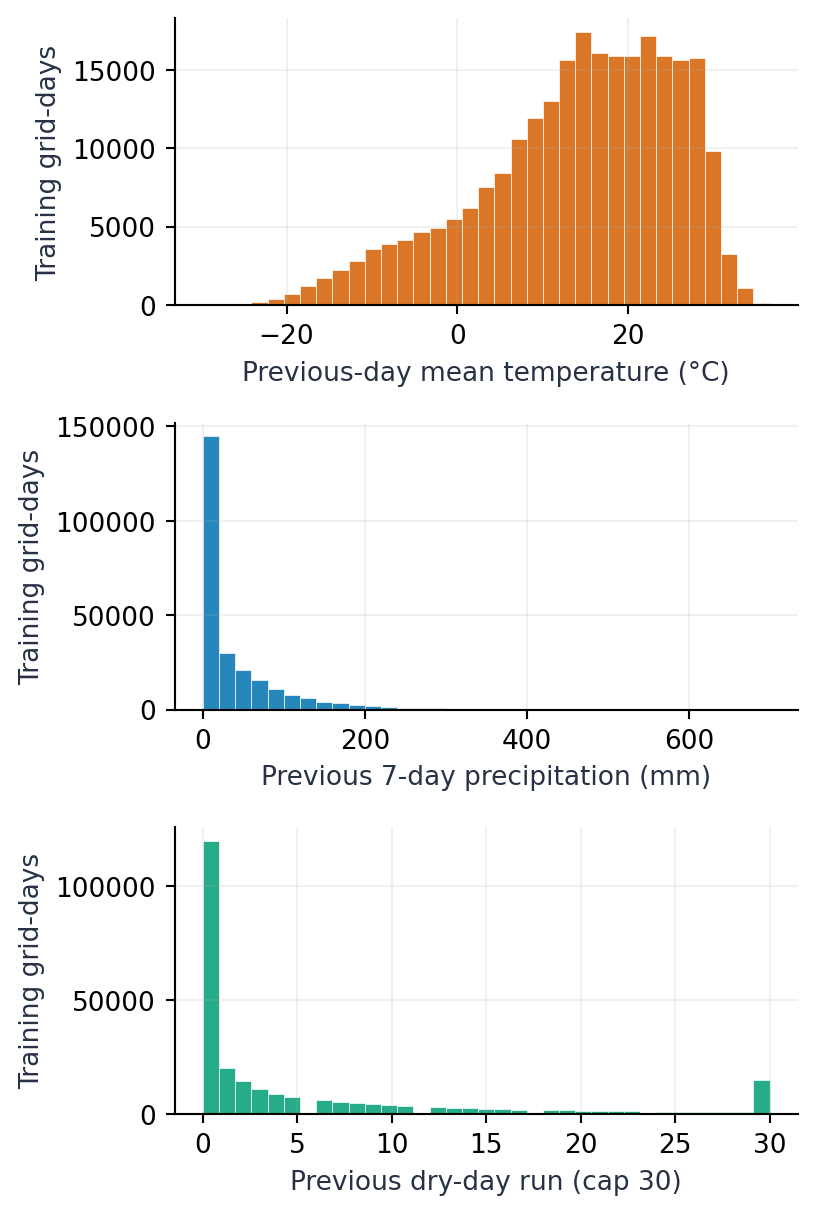

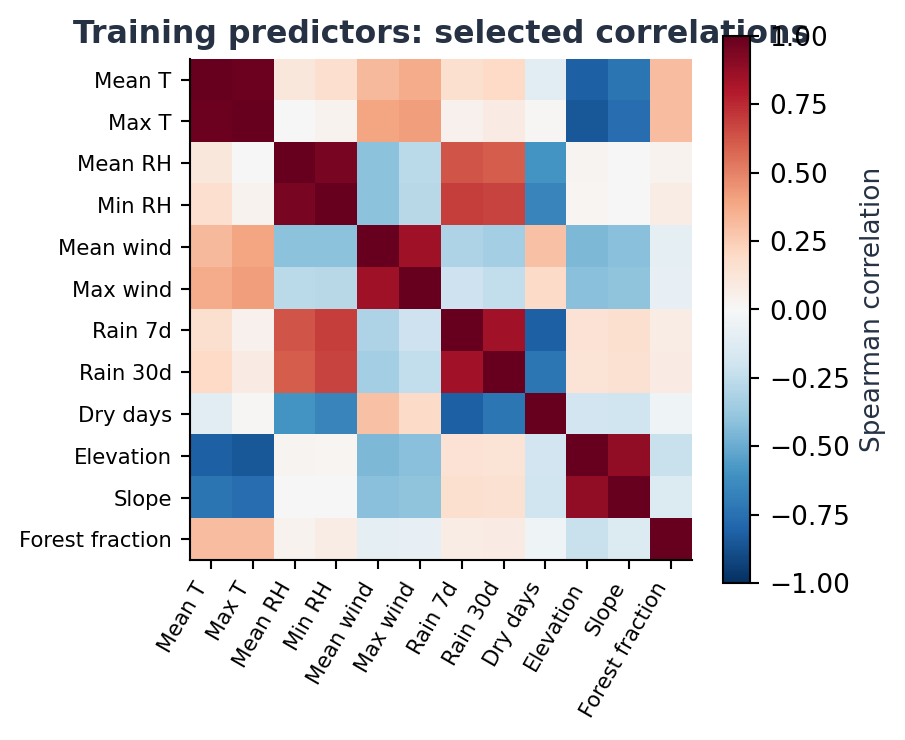

In [4]:
from IPython.display import display, Image
for name in ['preparation_flow','coverage_counts','imbalance','distributions','correlation']:
    display(Image(filename=str(analysis.BASE / 'overleaf/images' / (name + '.png'))))

## 4. Fit the four model families and controlled preprocessing variants

Twelve main candidates use class weighting. Configuration selection uses 2015 AP; binary thresholds maximise validation F1. Accuracy-focused thresholds are a separate experiment. Scaling, PCA and SMOTE are fitted on training data only. PCA retains 95% of training variance; SMOTE uses five neighbours and a 0.10 minority/majority ratio.

`RETRAIN=True` repeats fitting, tuning, uncertainty, feature importance, weather ablation, geographic evaluation and the five preprocessing variants. It will overwrite this full-run output directory, but not earlier experiment snapshots or source observations.

In [5]:
print(inspect.getsource(analysis.ex.candidates))
print(inspect.getsource(analysis.extra))
if RETRAIN:
    analysis.ex.run(data, features)
    analysis.extra(data, features)
display(pd.read_csv(OUT / 'tuning.csv')[['model','configuration','fit_seconds','validation_ap','f1_threshold']])

def candidates():
    return {'Logistic regression':[make_pipeline(StandardScaler(),LogisticRegression(C=c,class_weight='balanced',max_iter=3000,random_state=42)) for c in [.01,.1,1]],
    'Linear SVM':[make_pipeline(StandardScaler(),LinearSVC(C=c,class_weight='balanced',dual=False,max_iter=10000,random_state=42)) for c in [.01,.1,1]],
    'Random forest':[RandomForestClassifier(n_estimators=150,max_depth=n,min_samples_leaf=10,class_weight='balanced_subsample',n_jobs=2,random_state=42) for n in [8,12,None]],
    'Gradient boosting':[HistGradientBoostingClassifier(max_iter=150,max_leaf_nodes=n,learning_rate=.08,l2_regularization=1,early_stopping=False,class_weight='balanced',random_state=42) for n in [7,15,31]]}

def extra(d,features):
    tr=d[d.split.eq('train')];va=d[d.split.eq('validation')];te=d[d.split.eq('test')]
    variants={
      'Unweighted Logistic':Pipeline([('scale',StandardScaler()),('model',LogisticRegression(C=1,max_iter=3000,random_state=42))]),
      'Weighted Logist

,model,configuration,fit_seconds,validation_ap,f1_threshold
0,Logistic regression,1,0.468548,0.059318,0.935325
1,Logistic regression,2,0.472361,0.059831,0.939618
2,Logistic regression,3,0.443944,0.059883,0.940054
3,Linear SVM,1,0.624149,0.064477,0.858585
4,Linear SVM,2,0.609332,0.064421,0.860784
5,Linear SVM,3,0.553397,0.064426,0.861009
6,Random forest,1,14.638141,0.036136,0.923661
7,Random forest,2,16.233344,0.035493,0.844701
8,Random forest,3,17.711590,0.041961,0.363203
9,Gradient boosting,1,2.350635,0.046104,0.922893


## 5. Compare measured results and prediction errors

Balanced accuracy is distinct from ordinary accuracy. No result is limited to a requested percentage. The later test is not used to choose the winning configuration.

,model,policy,configuration,split,accuracy,balanced_accuracy,average_precision,roc_auc,precision,recall,f1,threshold,tn,fp,fn,tp
1,Logistic regression,F1,3,test,0.959095,0.683999,0.354718,0.922478,0.467593,0.385742,0.422742,0.940054,38199,690,965,606
5,Linear SVM,F1,1,test,0.958082,0.703629,0.356525,0.922181,0.457454,0.427753,0.442105,0.858585,38092,797,899,672
9,Random forest,F1,3,test,0.954548,0.765927,0.451212,0.929585,0.434055,0.561426,0.489592,0.363203,37739,1150,689,882
13,Gradient boosting,F1,1,test,0.957884,0.754530,0.468531,0.937014,0.463280,0.534055,0.496156,0.922893,37917,972,732,839


,variant,split,seconds,accuracy,balanced_accuracy,average_precision,roc_auc,precision,recall,f1,threshold,tn,fp,fn,tp,pca_components
0,Unweighted Logistic,validation,0.247960,0.991574,0.624727,0.046096,0.904432,0.082148,0.256158,0.124402,0.106901,86086,581,151,52,21
1,Unweighted Logistic,test,0.301641,0.949110,0.766764,0.368631,0.923337,0.392794,0.569064,0.464778,0.106901,37507,1382,677,894,21
2,Weighted Logistic,validation,0.444549,0.994405,0.604031,0.059883,0.917701,0.116531,0.211823,0.150350,0.940054,86341,326,160,43,21
3,Weighted Logistic,test,0.492035,0.959095,0.683999,0.354718,0.922478,0.467593,0.385742,0.422742,0.940054,38199,690,965,606,21
4,PCA Weighted Logistic,validation,0.386938,0.993093,0.613202,0.050305,0.913557,0.095723,0.231527,0.135447,0.921966,86223,444,156,47,11
5,PCA Weighted Logistic,test,0.437407,0.952620,0.727053,0.340601,0.920153,0.407089,0.482495,0.441596,0.921966,37785,1104,813,758,11
6,SMOTE Logistic,validation,0.567266,0.991528,0.629618,0.049647,0.910280,0.084243,0.266010,0.127962,0.534362,86080,587,149,54,21
7,SMOTE Logistic,test,0.632969,0.952941,0.751043,0.363573,0.923754,0.416958,0.532145,0.467562,0.534362,37720,1169,735,836,21
8,PCA SMOTE Logistic,validation,0.496194,0.991815,0.629763,0.048884,0.911490,0.087662,0.266010,0.131868,0.511719,86105,562,149,54,11
9,PCA SMOTE Logistic,test,0.548762,0.945106,0.753686,0.340361,0.919230,0.362637,0.546149,0.435865,0.511719,37381,1508,713,858,11


,model,training_rows,evaluation_rows,positive_days,average_precision
0,Logistic regression,166362,86870,930,0.189597
1,Linear SVM,166362,86870,930,0.190484
2,Random forest,166362,86870,930,0.245443
3,Gradient boosting,166362,86870,930,0.290178


,model,training_rows,evaluation_rows,positive_days,average_precision,roc_auc
0,Logistic regression,104850,32120,262,0.139095,0.950400
1,Linear SVM,104850,32120,262,0.130417,0.950492
2,Random forest,104850,32120,262,0.195387,0.933531
3,Gradient boosting,104850,32120,262,0.222274,0.959490


,features,count,validation_ap
0,"Terrain, location and season",9,0.018902
1,Plus lagged weather,21,0.045621


,model,ap_lower,ap_upper,bootstrap_repeats
0,Logistic regression,0.117132,0.438920,200
1,Linear SVM,0.174344,0.436889,200
2,Random forest,0.247200,0.534825,200
3,Gradient boosting,0.268779,0.567781,200


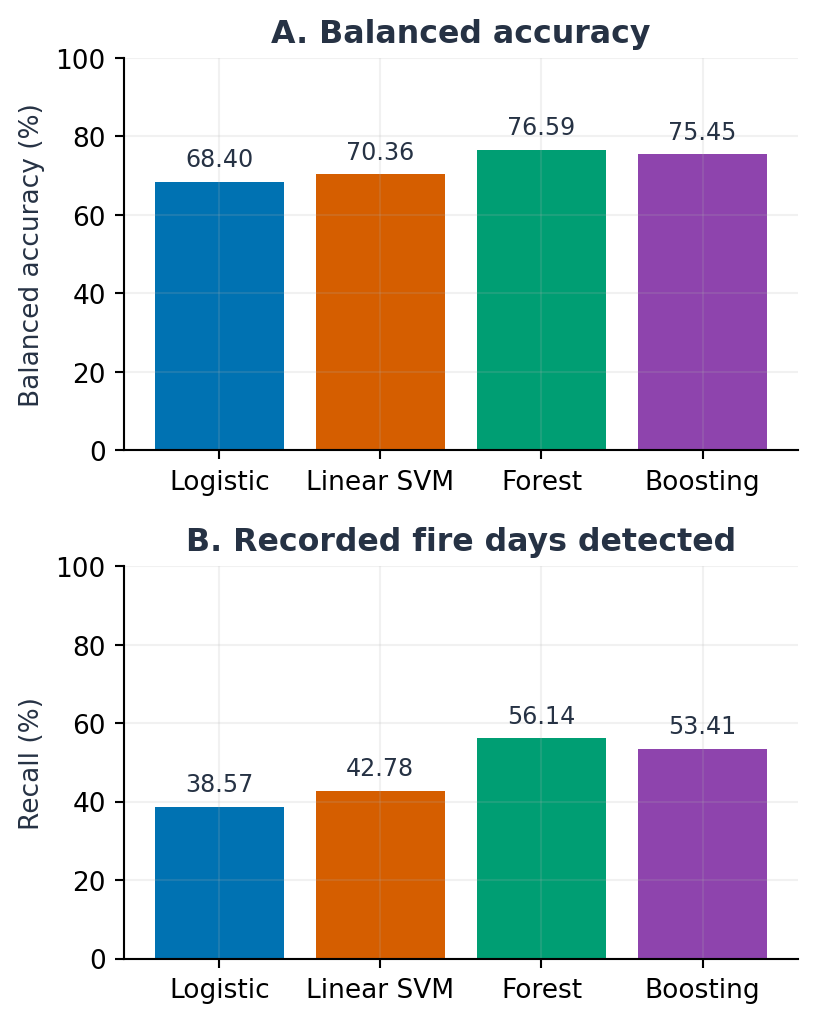

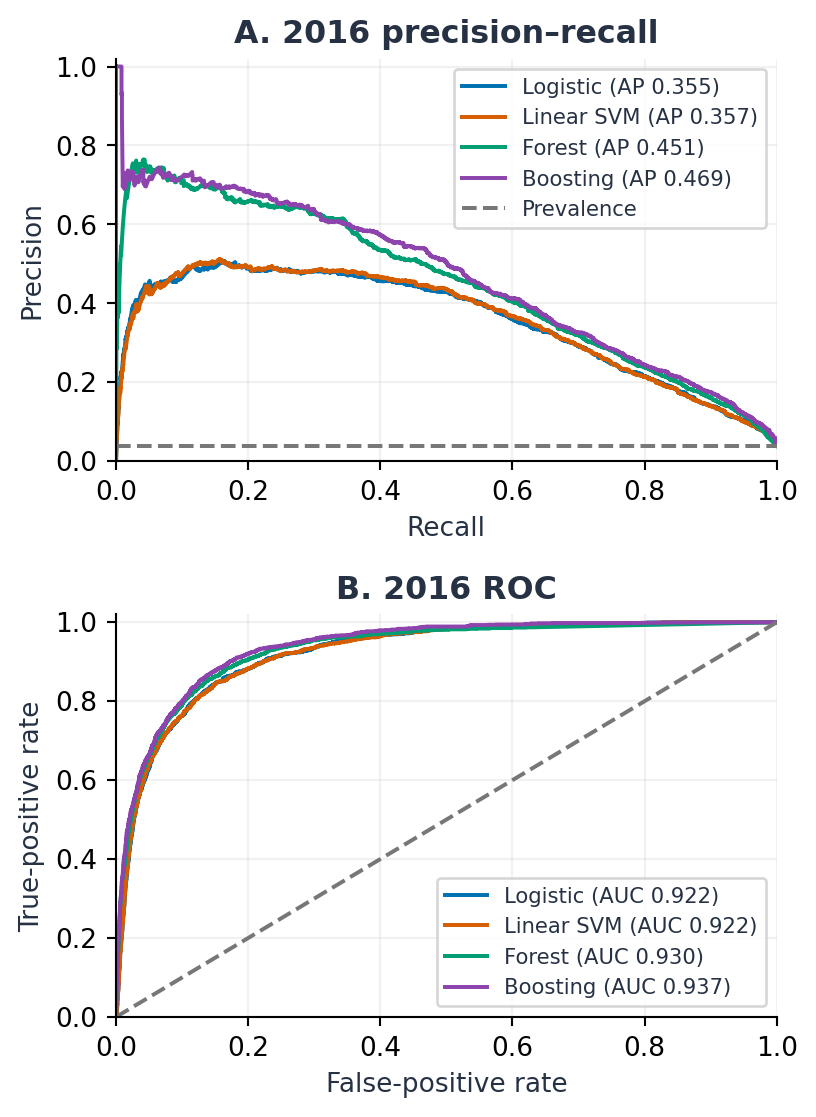

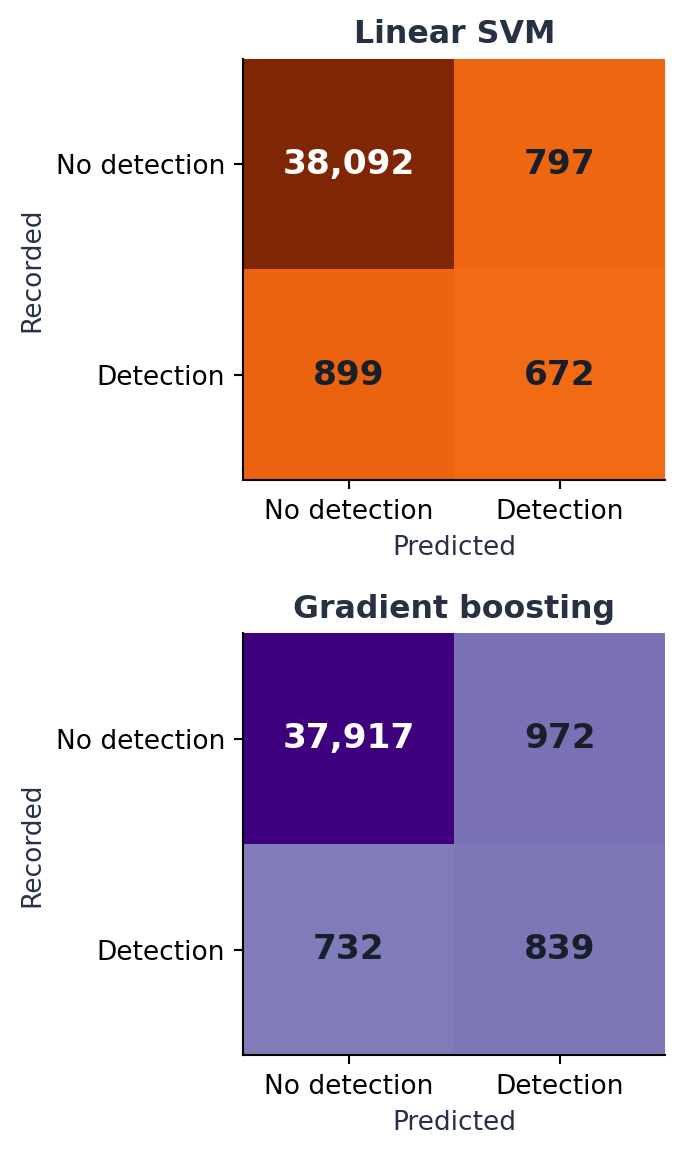

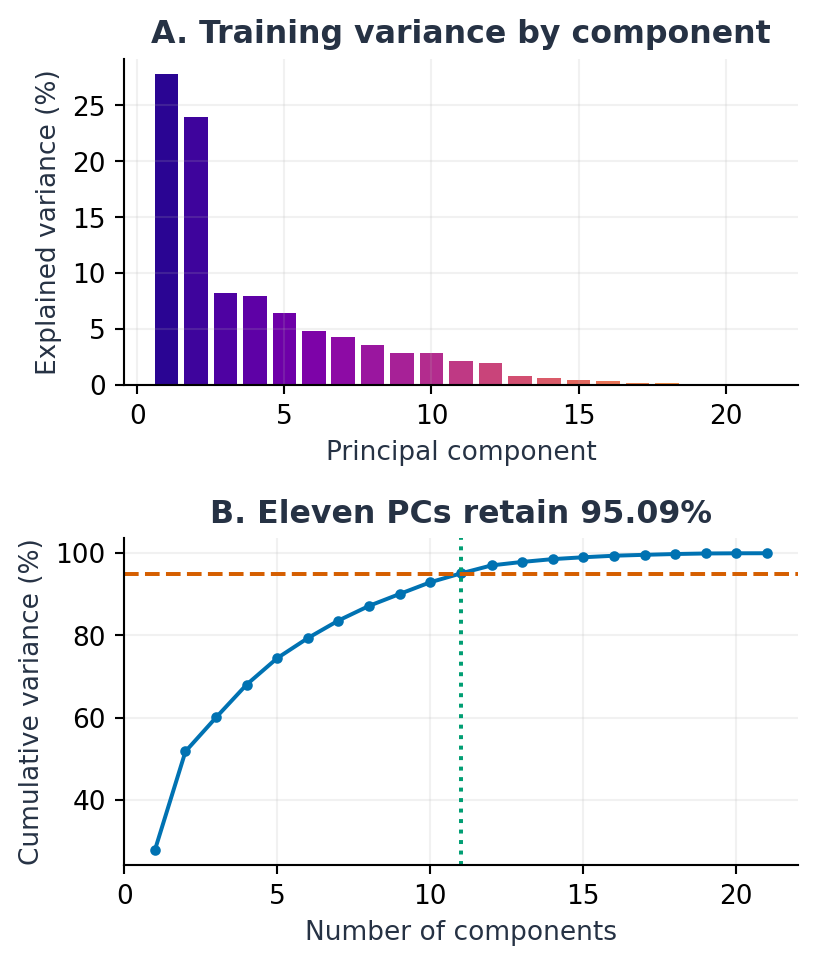

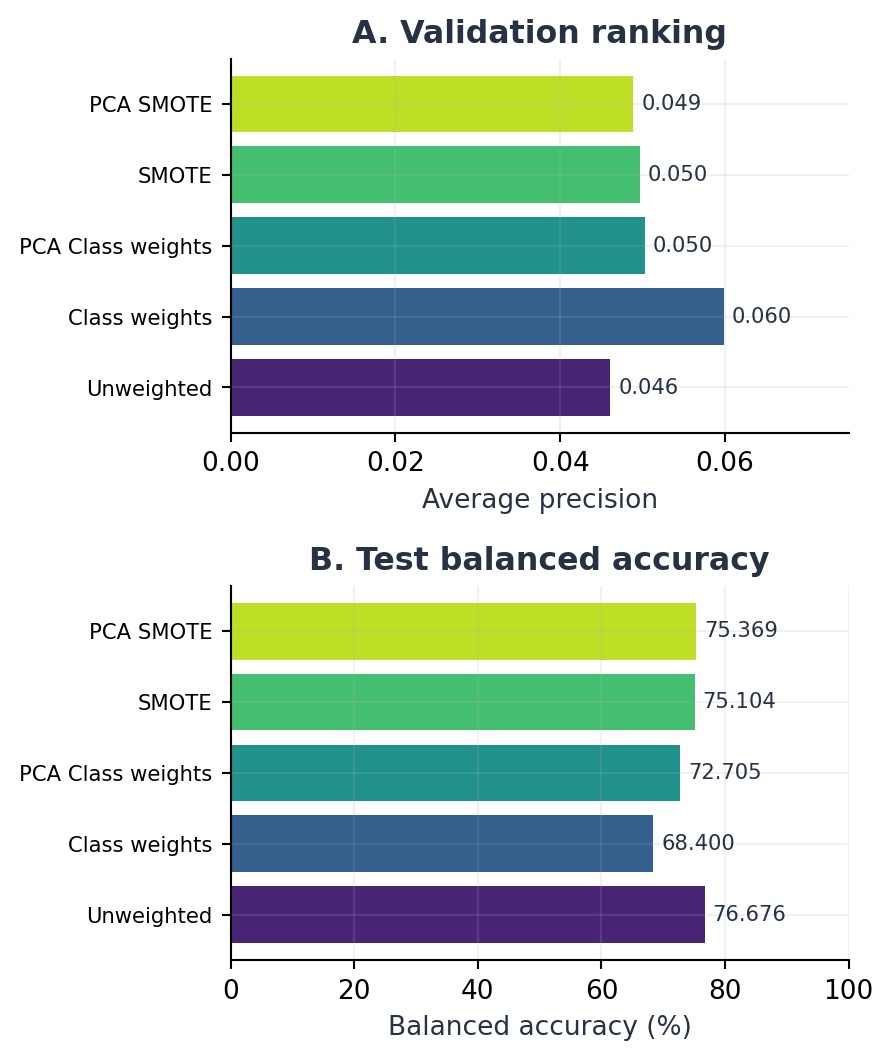

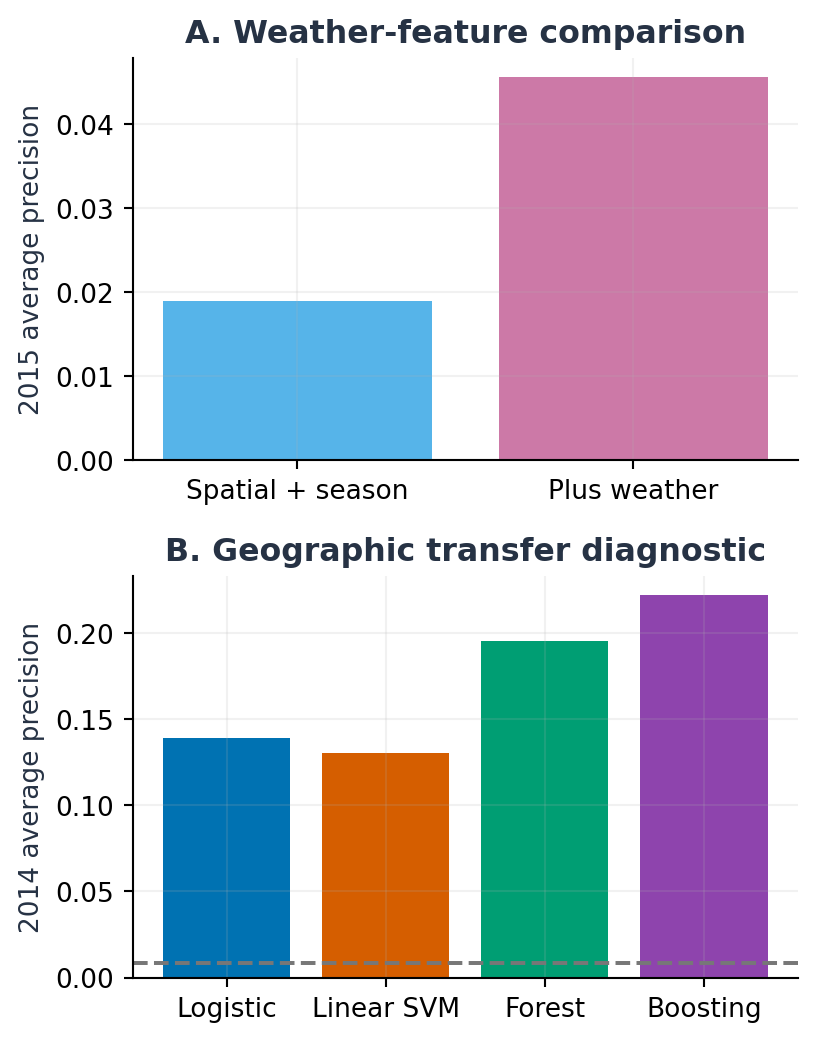

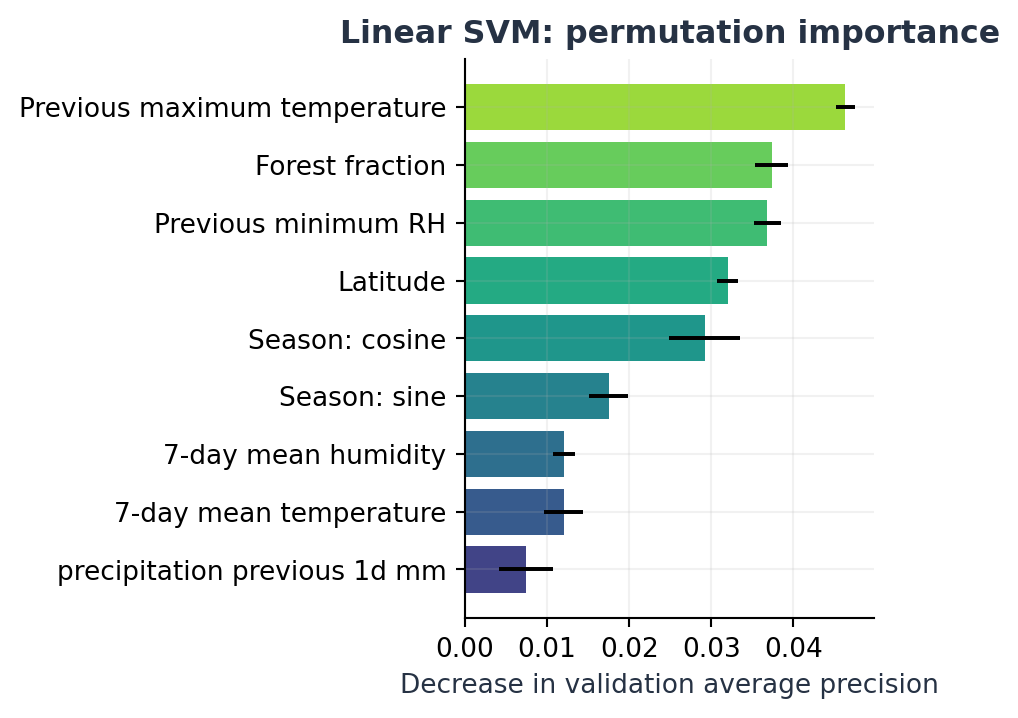

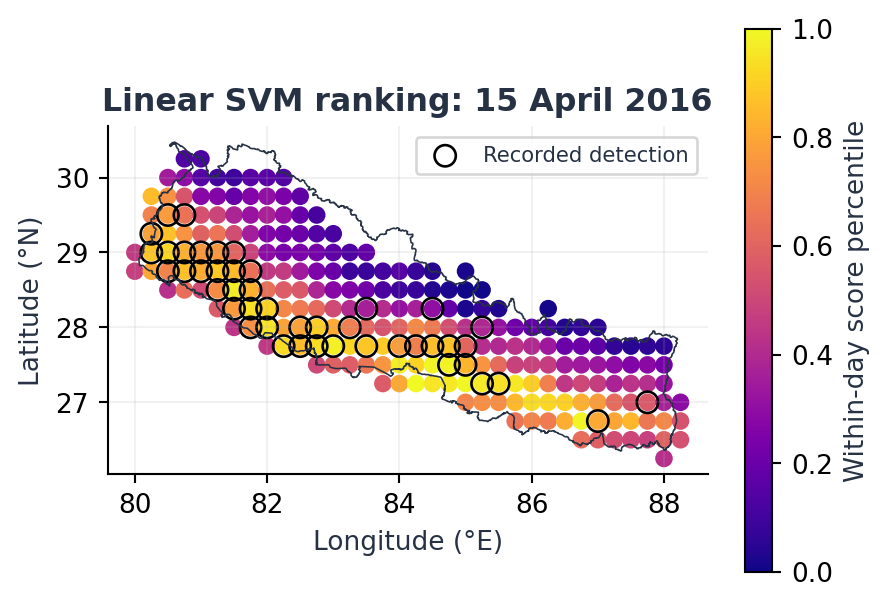

In [6]:
metrics = pd.read_csv(OUT / 'metrics.csv')
display(metrics.query("split == 'test' and policy == 'F1'"))
display(pd.read_csv(OUT / 'preprocessing_ablation.csv'))
display(pd.read_csv(OUT / 'forward_2014.csv'))
display(pd.read_csv(OUT / 'spatial_diagnostic.csv'))
display(pd.read_csv(OUT / 'ablation.csv'))
display(pd.read_csv(OUT / 'ap_intervals.csv'))
for name in ['accuracy_recall','curves','confusions','pca','preprocessing','diagnostics','importance','historical_map']:
    display(Image(filename=str(analysis.BASE / 'overleaf/images' / (name + '.png'))))

## 6. Reproducibility and limits

Satellite non-detections are unverified negatives; the full weather footprint does not make the fire archive complete. ERA5 is retrospective and coarse, forest cover is fixed at 2011, observations are dependent, and some test labels were seen in earlier work. The source manifest, data hash and settings identify the run. A later untouched observation period is required for stronger generalisation evidence.

In [7]:
summary = json.loads((OUT / 'summary.json').read_text())
digest = hashlib.sha256((DATA / 'forest_fire_grid_daily.csv').read_bytes()).hexdigest()
assert digest == summary['data_sha256']
print('Verified dataset hash:', digest)
display(pd.Series(summary))

Verified dataset hash: a796e2c9ca0b6ac40100c477d219e9e30ad02757b089402e05a1e1ffae7074b9


selected_by_validation_AP                                                 Linear SVM
selected_by_validation_accuracy                                        Random forest
data_sha256                        a796e2c9ca0b6ac40100c477d219e9e30ad02757b08940...
weather_locations                                                                238
features                                                                          21
provisional                                                                    False
run_date                                                                  2026-11-04
dtype: object